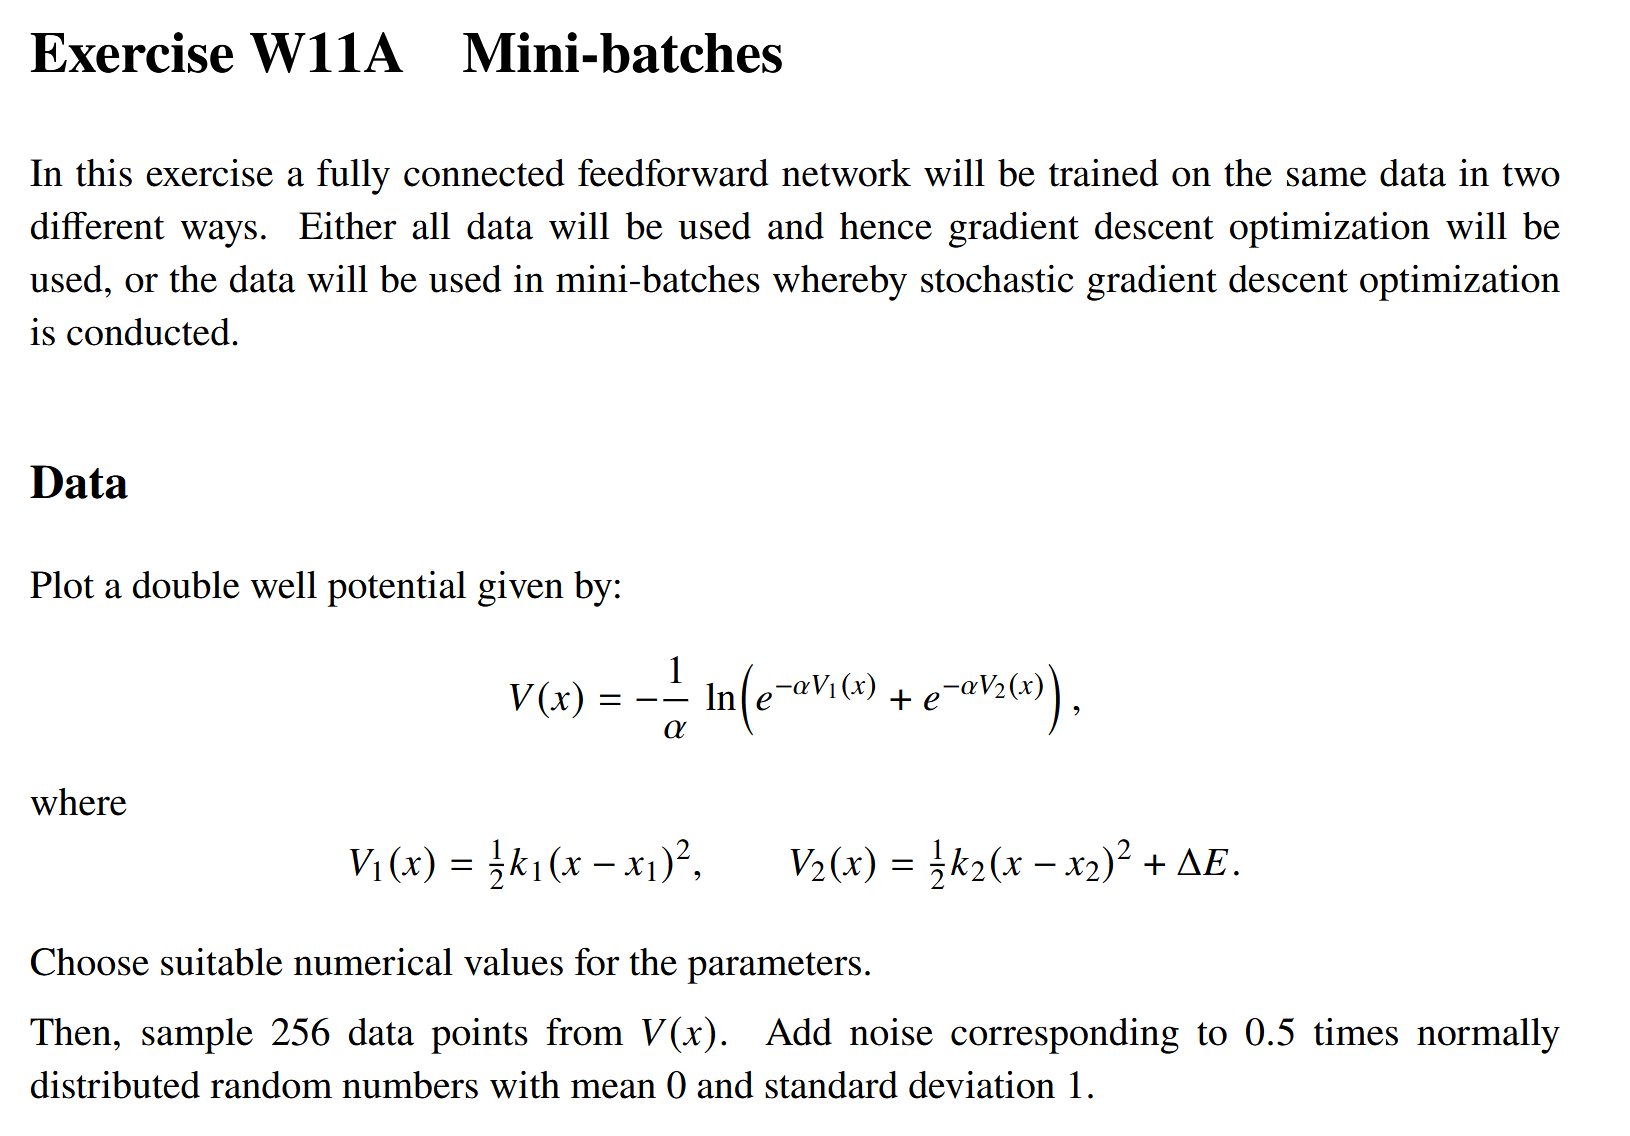

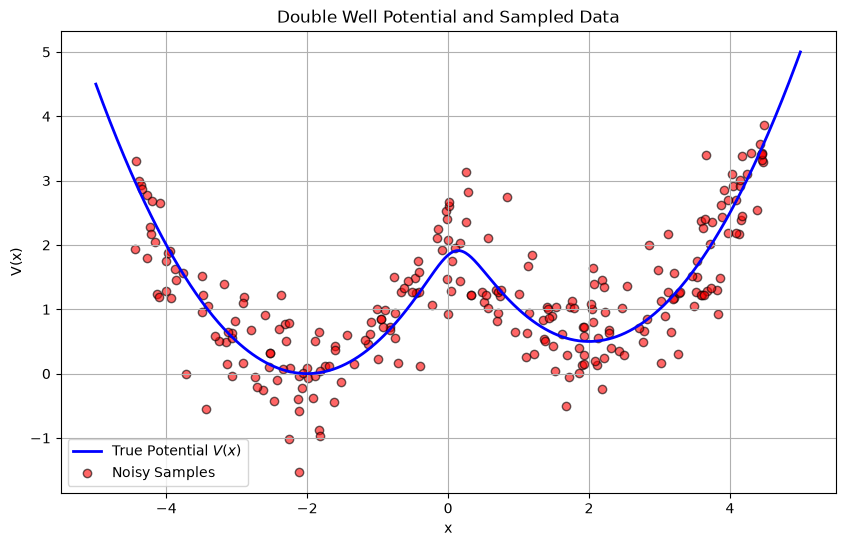

In [20]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 2.0
k1 = 1.0
k2 = 1.0
x1 = -2.0
x2 = 2.0
delta_E = 0.5 

def V1(x):
    return 0.5 * k1 * (x - x1)**2

def V2(x):
    return 0.5 * k2 * (x - x2)**2 + delta_E

def V(x):
    return - (1.0 / alpha) * np.log(np.exp(-alpha * V1(x)) + np.exp(-alpha * V2(x)))

x_smooth = np.linspace(-5, 5, 500)
y_smooth = V(x_smooth)

n_samples = 256
x_data = np.random.uniform(-4.5, 4.5, n_samples)

noise = 0.5 * np.random.normal(loc=0.0, scale=1.0, size=n_samples)
y_data = V(x_data) + noise

plt.figure(figsize=(10, 6))
plt.plot(x_smooth, y_smooth, label='True Potential $V(x)$', color='blue', linewidth=2)
plt.scatter(x_data, y_data, color='red', alpha=0.6, edgecolors='k', label='Noisy Samples')
plt.title('Double Well Potential and Sampled Data')
plt.xlabel('x')
plt.ylabel('V(x)')
plt.legend()
plt.grid(True)
plt.show()

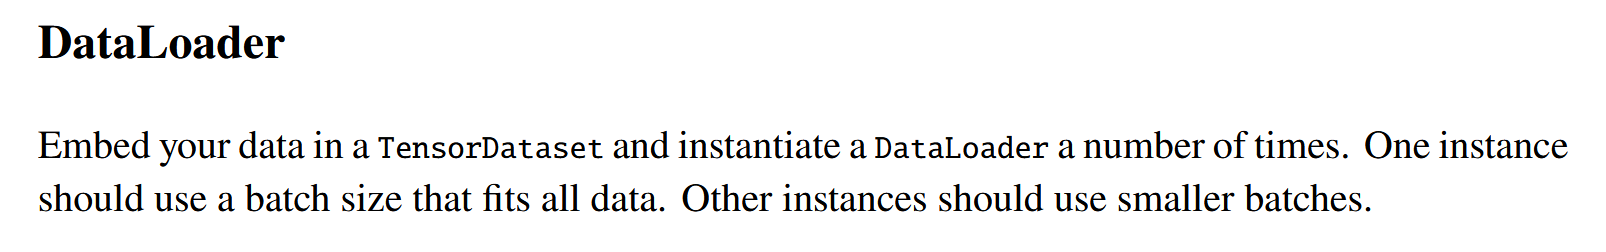

In [21]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import torch.optim as optim

x_tensor = torch.tensor(x_data, dtype=torch.float32)
y_tensor = torch.tensor(y_data, dtype=torch.float32)

dataset = TensorDataset(x_tensor, y_tensor)

dataloader_full = DataLoader(dataset, batch_size=len(dataset), shuffle=True)

dataloader_32 = DataLoader(dataset, batch_size=32, shuffle=True)
dataloader_64 = DataLoader(dataset, batch_size=64, shuffle=True)

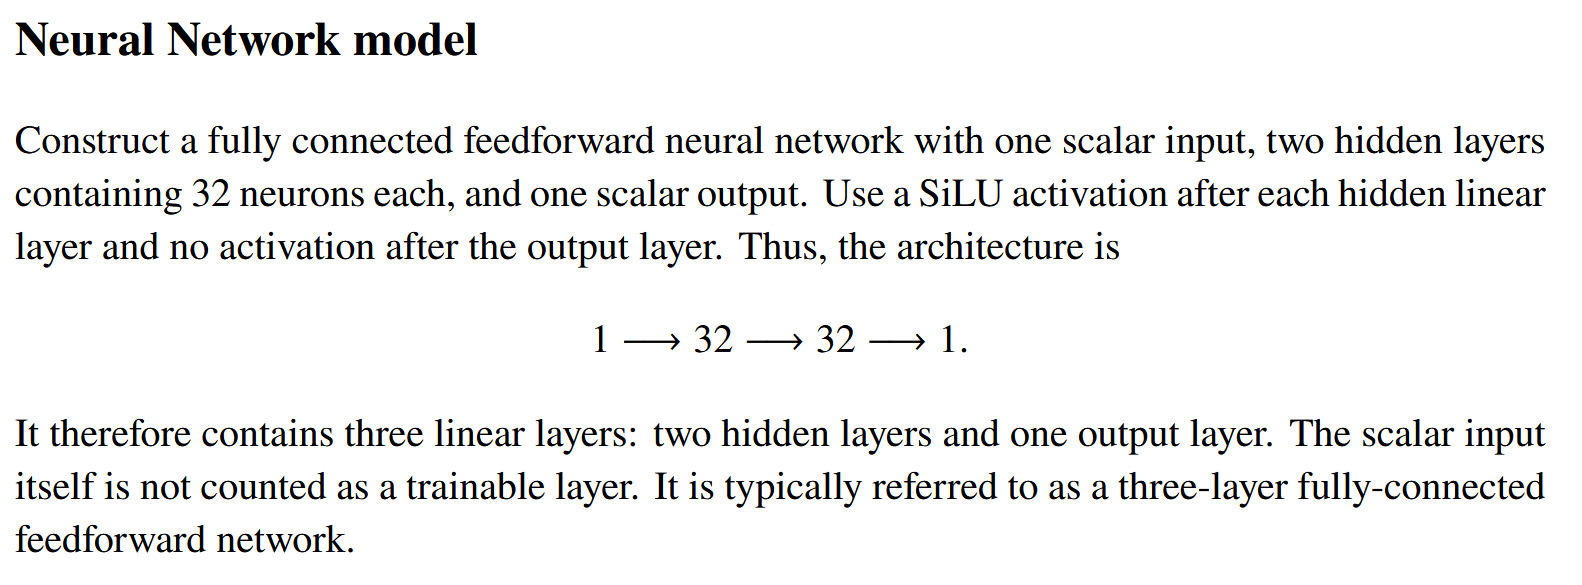

In [22]:
from models import *

model = LinearSiLUModule(hidden=32, layers=1)

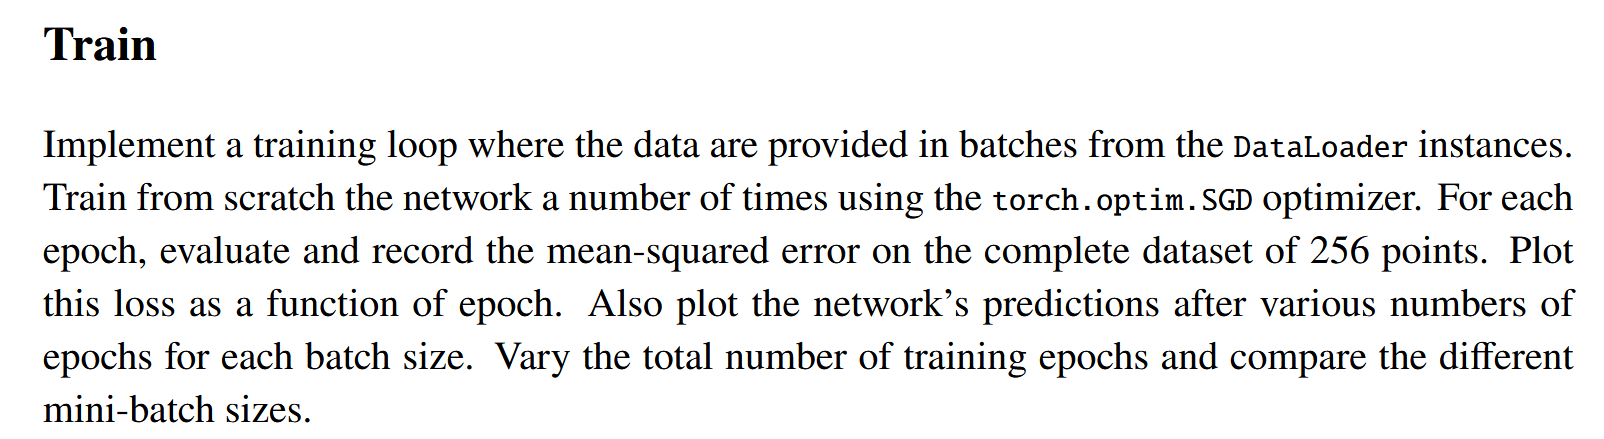

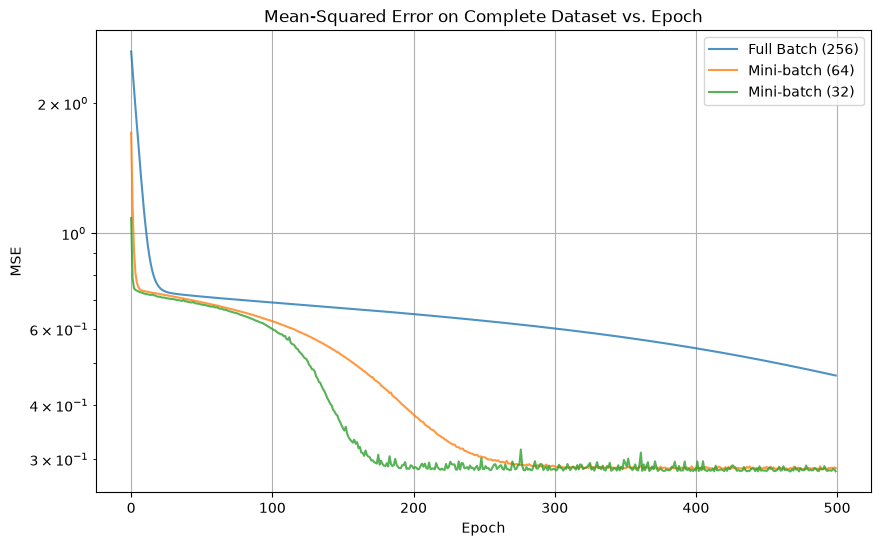

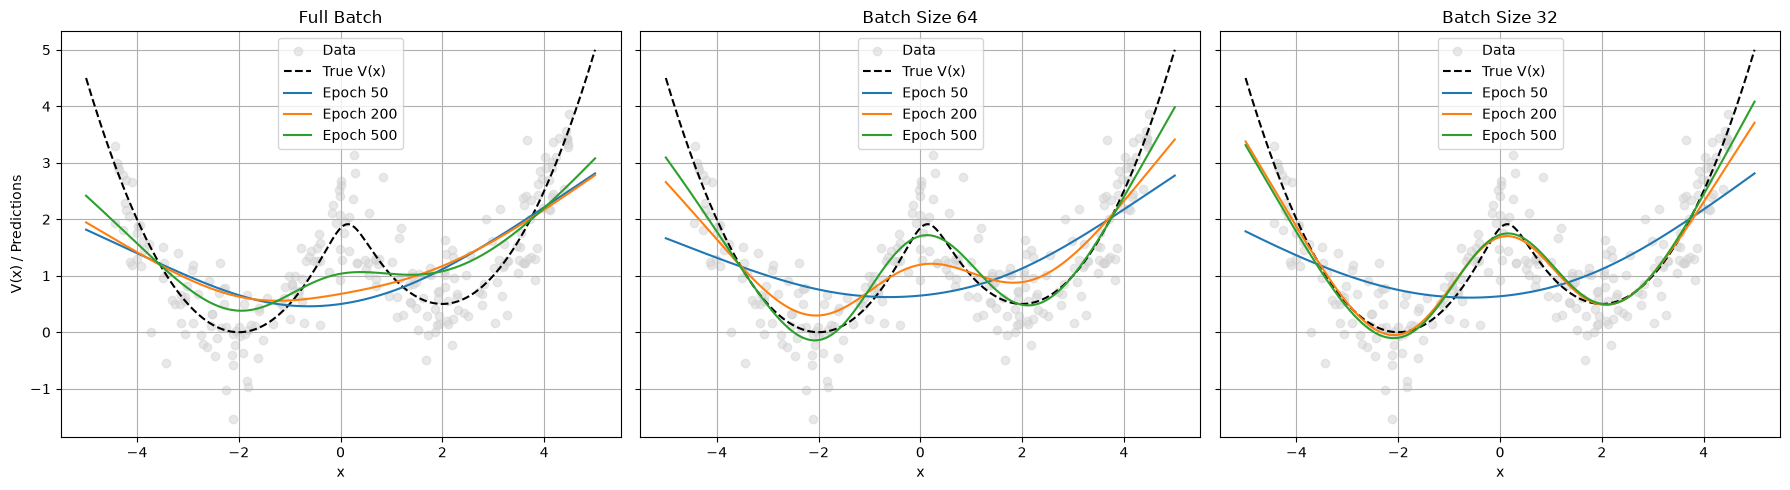

In [23]:
def train_and_evaluate(dataloader, total_epochs, lr=0.01, capture_epochs=None):
    if capture_epochs is None:
        capture_epochs = [50, 200, 500]
        
    model = LinearSiLUModule(hidden=32, layers=1)
    optimizer = optim.SGD(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    
    mse_history = []
    predictions_history = {}
    
    x_smooth_tensor = torch.tensor(x_smooth, dtype=torch.float32)
    
    for epoch in range(1, total_epochs + 1):
        model.train()
        for batch_x, batch_y in dataloader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            
            loss = criterion(outputs, batch_y)
            
            loss.backward()
            optimizer.step()
            
        model.eval()
        with torch.no_grad():
            full_dataset_pred = model(x_tensor)
            
            full_mse = criterion(full_dataset_pred, y_tensor).item()
            
            mse_history.append(full_mse)
            
            if epoch in capture_epochs:
                smooth_pred = model(x_smooth_tensor).squeeze().numpy()
                predictions_history[epoch] = smooth_pred
                
    return mse_history, predictions_history

total_epochs = 500
eval_checkpoints = [50, 200, 500]

loss_full, preds_full = train_and_evaluate(dataloader_full, total_epochs, capture_epochs=eval_checkpoints)
loss_64, preds_64 = train_and_evaluate(dataloader_64, total_epochs, capture_epochs=eval_checkpoints)
loss_32, preds_32 = train_and_evaluate(dataloader_32, total_epochs, capture_epochs=eval_checkpoints)

plt.figure(figsize=(10, 6))
plt.plot(loss_full, label='Full Batch (256)', alpha=0.8)
plt.plot(loss_64, label='Mini-batch (64)', alpha=0.8)
plt.plot(loss_32, label='Mini-batch (32)', alpha=0.8)
plt.title('Mean-Squared Error on Complete Dataset vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
dataloaders_results = [
    ('Full Batch', preds_full),
    ('Batch Size 64', preds_64),
    ('Batch Size 32', preds_32)
]

for i, (title, preds) in enumerate(dataloaders_results):
    axes[i].scatter(x_data, y_data, color='lightgray', alpha=0.5, label='Data')
    axes[i].plot(x_smooth, y_smooth, color='black', linestyle='--', label='True V(x)')
    
    for epoch, pred_y in preds.items():
        axes[i].plot(x_smooth, pred_y, label=f'Epoch {epoch}')
        
    axes[i].set_title(title)
    axes[i].set_xlabel('x')
    if i == 0:
        axes[i].set_ylabel('V(x) / Predictions')
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

## **Reflection**

* **Progress by Epoch vs. Steps:** Mini-batches lower loss faster *per epoch* because they update parameters multiple times per data pass. Conversely, full-batch training converges in fewer *total steps* because every update uses the true, exact gradient rather than a noisy estimate.


* **More Updates per Epoch:** An epoch is one complete pass through the training data. Smaller batches divide this data into more segments, forcing the optimizer to update parameters after each segment rather than just once at the end.


* **Cost vs. Noise Trade-off:** Large batches are computationally expensive to calculate but provide a precise gradient direction. Small batches are very cheap to compute, but introduce noise because they only provide a rough estimate of the true gradient.


* **Moderate vs. Small Batches:** Moderate mini-batches strike an efficient balance, providing a reliable gradient direction while keeping computational costs low. Very small mini-batches are too heavily skewed by individual data points, producing erratic, chaotic gradients that stall optimization.